<div style="border: 3px solid #0d3b0d; border-radius: 10px; overflow: hidden; margin-bottom: 20px; font-family: Arial, sans-serif;">

  <!-- Banner Institucional -->
  <div style="background-color: #006633; padding: 0;">
    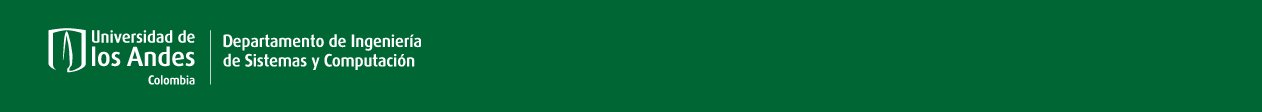
  </div>

  <!-- Titulo del laboratorio -->
  <div style="background-color: #ffffff; padding: 15px 20px; text-align: center;">
    <h2 style="margin: 0; color: #1a1a1a; font-size: 18px;">AI Security - Laboratorio 4 · Sesión 10</h2>
    <p style="margin: 4px 0 0 0; color: #555; font-size: 13px;">Ataques Adversariales de Evasión  (Adversarial ML)</p>
    <p style="margin: 4px 0 0 0; color: #555; font-size: 12px;">Maestr&iacute;a en Seguridad de la Informaci&oacute;n (MESI)</p>
  </div>

  <!-- Aviso de propiedad intelectual -->
  <div style="background-color: #f5f5f0; padding: 12px 20px; border-top: 1px solid #ddd; font-size: 11px; color: #444; line-height: 1.5;">
    <strong>Propiedad Intelectual - Universidad de los Andes</strong><br>
    Este material es propiedad exclusiva de la Universidad de los Andes (Bogot&aacute;, Colombia) y ha sido desarrollado para el programa de Maestr&iacute;a en Seguridad de la Informaci&oacute;n (MESI), Departamento de Ingenier&iacute;a de Sistemas y Computaci&oacute;n. Todos los derechos reservados &copy; 2026.<br><br>
    <strong>Condiciones de uso:</strong> Este material se distribuye exclusivamente a los estudiantes matriculados en el curso AI Security del programa MESI y est&aacute; protegido por las leyes colombianas de derechos de autor (Ley 23 de 1982 y Ley 1915 de 2018) y por las disposiciones aplicables de propiedad intelectual de la Universidad de los Andes. Queda estrictamente prohibida su reproducci&oacute;n, distribuci&oacute;n, modificaci&oacute;n, publicaci&oacute;n o transmisi&oacute;n total o parcial, en cualquier forma o medio, sin la autorizaci&oacute;n previa y por escrito de la Universidad de los Andes. El incumplimiento de estas condiciones podr&aacute; dar lugar a las acciones disciplinarias, civiles y penales correspondientes.
  </div>

</div>

# **Laboratorio 4: Ataques Adversariales de Evasion (Adversarial ML)**

**Curso:** AI Security - MESI

## **Objetivos de Aprendizaje**

Al completar este laboratorio, el estudiante será capaz de:

1. Comprender el modelo de amenaza de los ataques adversariales de evasión y su relevancia en ciberseguridad
2. Utilizar la librería Adversarial Robustness Toolbox (ART) para ejecutar ataques sobre modelos reales
3. Implementar y comparar cuatro ataques de caja blanca: FGSM, BIM, PGD y DeepFool
4. Analizar cuantitativamente el impacto de cada ataque en la precisión del modelo víctima
5. Visualizar e interpretar ejemplos adversariales en el contexto de malware como imagen

---

## **Aviso Legal y Uso de Datos**

### **Propósito Academico**

Este laboratorio se desarrolla exclusivamente con **fines académicos y educativos** en el marco del curso de AI Security - MESI de la Universidad de los Andes. El contenido, técnicas y herramientas presentadas están diseñadas para la enseñanza de conceptos de Adversarial Machine Learning aplicados a ciberseguridad.

### **Modelo Utilizado**

Este laboratorio reutiliza el modelo CNN entrenado en el **Laboratorio 3** sobre el dataset **Malimg**, que clasifica imagenes de malware binario en familias específicas. El dataset Malimg fue publicado originalmente por Nataraj et al. (2011) y es de uso libre para investigación académica.

### **Limitaciones y Responsabilidad**

- Las técnicas de ataque adversarial presentadas aquí son para **propósitos educativos** únicamente
- El uso de estás técnicas contra modelos en producción sin autorización es ilegal y antético
- No se deben desplegar modelos vulnerables en entornos de producción sin evaluación de robustez previa
- El uso indebido de las técnicas aquí presentadas es responsabilidad exclusiva del usuario
- Este material se rige por las políticas académicas de la Universidad de los Andes

---

## **Metodología: Ciclo CRISP-DM**

Este laboratorio sigue la metodología **CRISP-DM (Cross-Industry Standard Process for Data Mining)**, adaptada al contexto de seguridad ofensiva de modelos ML:

1. **Comprensión del Negocio (Business Understanding):** Entender el modelo de amenaza de los ataques adversariales en ciberseguridad
2. **Comprensión de los Datos (Data Understanding):** Examinar el modelo víctima y el espacio de entrada (imágenes de malware)
3. **Preparación de los Datos (Data Preparation):** Cargar y preparar el modelo y los datos de prueba
4. **Modelado (Modeling):** Implementar los ataques FGSM, BIM, PGD y DeepFool usando ART
5. **Evaluación (Evaluation):** Medir el impacto de cada ataque y comparar su efectividad
6. **Despliegue (Deployment):** Reflexionar sobre implicaciones para el hardening de modelos en producción

A medida que avance en el laboratorio, identifique en que fase de CRISP-DM se encuentra en cada sección.

## **Contexto: La Nueva Superficie de Ataque**

Los modelos de Machine Learning, incluyendo los clasificadores de malware que estudiamos en el Laboratorio 3, no son inmunes a ataques. A diferencia de los ataques a sistemas de información tradicionales (explotación de vulnerabilidades de software, inyeccion SQL, etc.), los **ataques adversariales** apuntan directamente al proceso de inferencia del modelo.

### **El Problema de los Ejemplos Adversariales**

Un **ejemplo adversarial** es una entrada que ha sido modificada de forma mínima e imperceptible (para un humano), pero que causa que el modelo produzca una predicción incorrecta con alta confianza. Este fenómeno fue documentado sistemáticamente por primera vez por Szegedy et al. (2013) y desde entonces ha sido objeto de estudio intensivo.

En el contexto de malware:

- **Escenario:** Operamos sobre la imagen en escala de grises que representa el binario (el mapa de bytes del Lab 3).
- **Objetivo:** Modificar mínimamente la imagen para que el clasificador asigne una familia incorrecta o reduzca su confianza.
- **Advertencia conceptual importante:** En este laboratorio atacamos en el **espacio de features** (los píxeles de la imagen). Estas perturbaciones a nivel de píxel **rompen, en general, la ejecutabilidad y la funcionalidad del binario real**. Es decir, los ejemplos adversariales que generaremos **no son malware funcional**: son una herramienta para estudiar la fragilidad del modelo. Un ataque realizable en el mundo real opera en el **espacio del problema** (modificar el binario preservando su funcionalidad), tema que abordamos en la siguiente nota.

### **Taxonomía de Ataques (según MITRE ATLAS)**

El framework **MITRE ATLAS** (Adversarial Threat Landscape for Artificial-Intelligence Systems) clasifica los ataques a modelos ML. Los ataques de evasion corresponden a la tactica **AML.TA0000 - ML Model Access** y la técnica **AML.T0015 - Evade ML Model**, ejecutados durante la fase de inferencia.

Según el conocimiento del atacante, los ataques se clasifican en:

- **Caja Blanca (White-box):** El atacante conoce la arquitectura del modelo, los pesos y puede calcular gradientes. Los ataques FGSM, BIM, PGD y DeepFool son de caja blanca.
- **Caja Negra (Black-box):** El atacante solo puede consultar el modelo y observar sus salidas. Generalmente se explotan propiedades de transferibilidad de ataques de caja blanca.

En este laboratorio nos enfocamos en ataques de **caja blanca**, que representan el escenario de mayor capacidad del atacante y nos permiten entender los fundamentos matemáticos de cada método.

### **Para profundizar:**
- [MITRE ATLAS Framework](https://atlas.mitre.org/) - Taxonomía de ataques a sistemas ML
- [Szegedy et al. (2013) - Intriguing properties of neural networks](https://arxiv.org/abs/1312.6199) - Paper original de ejemplos adversariales
- [Goodfellow et al. (2014) - Explaining and Harnessing Adversarial Examples](https://arxiv.org/abs/1412.6572) - Paper de FGSM
- [ART Documentation](https://adversarial-robustness-toolbox.readthedocs.io/) - Librería que usaremos

### **Espacio de features vs. espacio del problema (feature-space vs problem-space)**

Esta distinción es central en la seguridad de la IA aplicada a malware y conviene tenerla clara antes de ejecutar los ataques.

- **Espacio de features (lo que hace este laboratorio):** perturbamos directamente la representación que recibe el modelo, en nuestro caso los píxeles de la imagen. Es el escenario clásico de los ataques adversariales en visión por computador. Nos permite entender los mecanismos matemáticos de la evasión (gradientes, epsilon, normas L2 y L-infinito) y medir qué tan frágil es el clasificador.

- **Espacio del problema (el ataque realista):** modificar el objeto real (el binario ejecutable) de forma que **siga siendo funcional y ejecutable**, y que además produzca la evasión deseada. Esto es mucho más difícil, porque en un binario no se puede cambiar cualquier byte sin riesgo de corromper el archivo o alterar su comportamiento. Pierazzi et al. (2020) formalizaron este problema e identificaron las restricciones que un ataque real debe respetar (transformaciones disponibles, preservación de la semántica, robustez al preprocesamiento y plausibilidad).

**¿Cómo se ataca de verdad un binario preservando su funcionalidad?** Existen técnicas específicas, por ejemplo:
- Añadir bytes al final del archivo (*append/padding*) sin tocar el código ejecutable.
- Usar el *slack space* (huecos entre secciones del binario).
- Manipular campos no utilizados de la cabecera del PE (por ejemplo, el DOS header).
- Inyectar secciones nuevas con contenido benigno.

Estas técnicas se estudian en trabajos como Suciu et al. (2019), Demetrio et al. (2021) y Anderson et al. (2018), y existen librerías especializadas como `secml-malware` que las implementan (a diferencia de ART, que es de propósito general).

**En resumen:** lo que aprenderás aquí (atacar el modelo en el espacio de features) es la base conceptual indispensable. El salto a un ataque ejecutable en el mundo real requiere las técnicas de espacio del problema mencionadas. Mantener esta distinción es lo que separa "engañar a un modelo en el laboratorio" de "evadir un antivirus real".

---

## **1. Configuración del Entorno**

Instalamos las librerías necesarias. La librería central es **Adversarial Robustness Toolbox (ART)**, desarrollada por IBM Research y mantenida como proyecto de código abierto.

In [ ]:
import os
import sys

# Agrega la ruta de ejecutables y paquetes locales al PATH y sys.path del sistema
local_bin = os.path.expanduser("~/.local/bin")
if local_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{local_bin}:{os.environ['PATH']}"

user_site = os.path.expanduser("~/.local/lib/python3.10/site-packages")
if user_site not in sys.path:
    sys.path.append(user_site)

In [ ]:
%pip install -q --user adversarial-robustness-toolbox tensorflow numpy matplotlib seaborn scikit-learn kagglehub Pillow

Importaciones

In [ ]:
# Importaciones del laboratorio
import os
import time
import warnings
from pathlib import Path

# Nivel de logs de TensorFlow (debe fijarse antes de importarlo): 2 = solo errores
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

# Manejo y visualización de datos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

# scikit-learn
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

# Descarga del dataset
import kagglehub

# Adversarial Robustness Toolbox (ART)
import art
from art.estimators.classification import KerasClassifier
from art.attacks.evasion import (
    FastGradientMethod,
    BasicIterativeMethod,
    ProjectedGradientDescent,
    DeepFool,
)

# Crecimiento dinámico de memoria en GPU (si hay alguna disponible)
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        # Solo se puede configurar antes de inicializar la GPU
        print(f"No se pudo habilitar memory growth en {gpu.name}: {e}")

# Salida limpia: warnings de Python y logger de TensorFlow
# (los avisos de ART se emiten por logging, así que se siguen viendo; se necesitan para la Pregunta 4)
warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')

# Estilo de las visualizaciones
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

# Semilla para reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print(f"TensorFlow: {tf.__version__}")
print(f"Keras:      {keras.__version__}")
print(f"ART:        {art.__version__}")
print(f"GPUs disponibles: {len(gpus)}")

### **Documentación de Librerías:**
Si no estás familiarizado con alguna librería, consulta:
- [ART - Documentación oficial](https://adversarial-robustness-toolbox.readthedocs.io/en/latest/)
- [ART - GitHub y ejemplos](https://github.com/Trusted-AI/adversarial-robustness-toolbox/tree/main/notebooks)
- [TensorFlow / Keras - User Guide](https://www.tensorflow.org/guide/keras)
- [Matplotlib - Gallery](https://matplotlib.org/stable/gallery/index.html)

---

## **2. Carga del Modelo Víctima (Laboratorio 3)**

### **CRISP-DM: Comprensión de los Datos y el Modelo**

El modelo víctima es la CNN que entrenaste en el Laboratorio 3 para clasificar familias de malware a partir de imágenes en escala de grises. Este modelo fue guardado al final de ese laboratorio.

**Antes de continuar, asegurate de:**
1. Tener el archivo del modelo guardado del Lab 3 (típicamente `malware_cnn.h5` o `malware_cnn.keras`)
2. Tener el dataset Malimg disponible en el mismo directorio o en la ruta configurada

Si no tienes el modelo del Lab 3, la celda a continuación incluye código para re-entrenarlo rápidamente con una arquitectura equivalente.

In [ ]:
# Definicion de parametros globales del laboratorio
# Ajusta estos valores según la configuracion de tu Lab 3

IMG_SIZE = 128           # Tamaño de la imagen cuadrada (pixeles)
N_CHANNELS = 1          # Escala de grises
N_CLASSES = 9           # Número de familias de malware
CLIP_MIN = 0.0          # Minimo valor de pixel (normalizado)
CLIP_MAX = 1.0          # Maximo valor de pixel (normalizado)
MODEL_PATH = 'advanced.h5'  # Modelo avanzado del Lab 3 (mejor accuracy)

print("Parámetros configurados:")
print(f"  Tamaño de imagen: {IMG_SIZE}x{IMG_SIZE}")
print(f"  Canales: {N_CHANNELS}")
print(f"  Número de clases: {N_CLASSES}")
print(f"  Rango de valores de pixel: [{CLIP_MIN}, {CLIP_MAX}]")

---

## **3. Carga y Preparación de los Datos de Prueba**

### **CRISP-DM: Preparación de los Datos**

Para evaluar los ataques necesitamos reproducir exactamente el mismo pipeline de datos utilizado en el Laboratorio 3. Descargamos el dataset Malimg desde Kaggle usando `kagglehub` y procesamos las imágenes con identica normalización, de modo que el modelo cargado y los datos de entrada sean completamente consistentes.

Los ataques adversariales solo tienen sentido sobre ejemplos que el modelo clasifica **correctamente** en condiciones normales (sin ataque). Si se evaluara sobre imágenes que el modelo ya falla, la tasa de éxito del ataque quedaría artificialmente inflada.

In [ ]:
# Descarga del dataset usando kagglehub
print("="*70)
print("DESCARGA DEL DATASET MALIMG")
print("="*70)
print("\nIniciando descarga desde Kaggle...")
print("Tamaño aproximado: 1GB")
print("Esto puede tardar 5-15 minutos dependiendo de tu conexion.\n")

dataset_path = kagglehub.dataset_download("ikrambenabd/malimg-original")

print("\n" + "="*70)
print("DATASET DESCARGADO EXITOSAMENTE")
print("="*70)
print(f"\nUbicación del dataset: {dataset_path}")
print("\nPuedes proceder con la exploración de datos.")

# Convertir a Path para facilitar navegacion
data_path = Path(dataset_path)

print("="*70)
print("ESTRUCTURA DEL DATASET")
print("="*70)
print("\nContenido del directorio raiz:\n")

items = list(data_path.iterdir())
for i, item in enumerate(items[:20], 1):
    item_type = "[DIR]" if item.is_dir() else "[FILE]"
    print(f"  {i:2d}. {item_type:6s} {item.name}")

if len(items) > 20:
    print(f"\n  ... y {len(items) - 20} elementos más")

print(f"\nTotal de elementos: {len(items)}")

In [ ]:
# Búsqueda y catalogación de todas las imágenes PNG del dataset

def find_all_images(root_path, extensión='.png'):
    return list(root_path.rglob(f'*{extensión}'))

all_images = find_all_images(data_path)

print("="*70)
print("BUSQUEDA DE IMAGENES")
print("="*70)
print(f"\nTotal de imágenes PNG encontradas: {len(all_images):,}")
print(f"\nPrimeros 10 ejemplos de rutas:")
for i, img in enumerate(all_images[:10], 1):
    print(f"  {i:2d}. {img}")

# Ver estructura del dataset
print("\nEstructura del dataset:")
for item in list(data_path.iterdir())[:20]:
    print(f"  {item}")
    if item.is_dir():
        sub_items = list(item.iterdir())[:5]
        for sub in sub_items:
            print(f"    - {sub.name}")

# Ver ejemplo de nombres de archivo
print("\nEjemplos de nombres de archivo:")
for img in all_images[:5]:
    print(f"  Ruta completa: {img}")
    print(f"  Nombre: {img.name}")
    print(f"  Parent: {img.parent.name}")
    print()

In [ ]:
# DataFrame con los metadatos de cada imagen del dataset

def extract_family(img_path):
    """En Malimg cada familia es una carpeta: .../<Familia>/<archivo>.png"""
    return Path(img_path).parent.name

df = pd.DataFrame({
    'path': [str(p) for p in all_images],
    'family': [extract_family(p) for p in all_images],
    'filename': [p.name for p in all_images],
})

print("="*70)
print("METADATOS DEL DATASET")
print("="*70)
print(f"\nTamaño del DataFrame: {df.shape}")
print(f"Número de familias: {df['family'].nunique()}")
print("\nPrimeras filas:")
print(df.head(10).to_string())
print("\nImágenes por familia:")
print(df['family'].value_counts().to_string())

In [ ]:
# Construcción de X_all e y_all (mismo preprocesamiento del Lab 3)

# Codificación de familias como enteros consecutivos desde 0 (LabelEncoder, igual que en el Lab 3)
encoder = LabelEncoder()
df['label'] = encoder.fit_transform(df['family'])
class_names = list(encoder.classes_)

# Número real de familias en el dataset descargado
N_CLASSES = len(class_names)

def load_image(path, img_size=IMG_SIZE):
    """Carga en escala de grises, redimensiona (LANCZOS, como en el Lab 3) y normaliza a [0, 1] en float32."""
    with Image.open(path) as img:
        img = img.convert('L').resize((img_size, img_size), Image.Resampling.LANCZOS)
        return np.asarray(img, dtype=np.float32) / 255.0

print(f"Cargando {len(df):,} imágenes...")
t0 = time.time()
X_all = np.stack([load_image(p) for p in df['path']])
X_all = X_all[..., np.newaxis]          # (N, IMG_SIZE, IMG_SIZE, 1): dimensión de canal
y_all = df['label'].to_numpy(dtype=np.int64)
print(f"Carga completada en {time.time() - t0:.1f} s")

print(f"\nX_all shape: {X_all.shape}")
print(f"X_all dtype: {X_all.dtype}")
print(f"X_all rango: [{X_all.min():.3f}, {X_all.max():.3f}]")
print(f"y_all shape: {y_all.shape}")
print(f"N_CLASSES actualizado: {N_CLASSES}")
print(f"\nClases: {class_names}")

In [ ]:
# Division en conjuntos de entrenamiento y prueba
# Usamos el mismo split del Lab 3 para consistencia con el modelo cargado

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_all
)

print(f"Conjunto de entrenamiento: {X_train.shape[0]:,} imágenes")
print(f"Conjunto de prueba: {X_test.shape[0]:,} imágenes")
print("\nDatos listos. Procede a cargar el modelo en la siguiente sección.")


In [ ]:
# CNN de respaldo: misma arquitectura que la CNN avanzada del Lab 3 (create_advanced_cnn)

def build_fallback_cnn(img_size, n_channels, n_classes):
    """
    4 bloques Conv2D -> BatchNorm -> ReLU -> MaxPool -> Dropout(0.25) con filtros
    crecientes (32, 64, 128, 256), GlobalAveragePooling2D y dos capas densas con
    Dropout(0.5) antes de la salida softmax.
    """
    model = models.Sequential(name='CNN_Respaldo')
    model.add(layers.Input(shape=(img_size, img_size, n_channels)))

    for filtros in [32, 64, 128, 256]:
        model.add(layers.Conv2D(filtros, (3, 3), padding='same'))
        model.add(layers.BatchNormalization())
        model.add(layers.Activation('relu'))
        model.add(layers.MaxPooling2D((2, 2)))
        model.add(layers.Dropout(0.25))

    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dense(256, activation='relu'))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(n_classes, activation='softmax'))

    # Mismo optimizador del Lab 3; pérdida "sparse" porque y_train / y_test son enteros (no one-hot)
    model.compile(
        optimizer=keras.optimizers.Adam(0.0005),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model

print("build_fallback_cnn definida. Arquitectura de referencia:")
build_fallback_cnn(IMG_SIZE, N_CHANNELS, N_CLASSES).summary()

In [ ]:
# Carga del modelo guardado del Laboratorio 3
# Si el archivo no existe, se activa el modelo de respaldo automáticamente.
# NOTA: El modelo de respaldo requiere que los datos ya esten cargados
# (X_train, y_train, X_test, y_test). Si esta celda se ejecuta antes que
# las celdas de datos, movela al final de la sección 3 o carga primero los datos.

if os.path.exists(MODEL_PATH):
    model = keras.models.load_model(MODEL_PATH)
    print(f"Modelo cargado exitosamente desde: {MODEL_PATH}")
    print("\nResumen de la arquitectura:")
    model.summary()
else:
    print(f"[ADVERTENCIA] No se encontro el modelo en: {MODEL_PATH}")
    print("Asegurate de haber completado el Lab 3 y guardado el modelo.")
    print("\nActivando modelo de respaldo para continuar el laboratorio...")
    print("Este modelo se entrenara ahora sobre el dataset Malimg.")
    print("NOTA: El modelo de respaldo requiere que los datos esten cargados.")
    print("      Si aun no ejecutaste las celdas de datos, ejecutalas primero")
    print("      y luego vuelve a correr esta celda.")
    try:
        model = build_fallback_cnn(IMG_SIZE, N_CHANNELS, N_CLASSES)
        model.fit(
            X_train, y_train,
            epochs=15,
            batch_size=32,
            validation_data=(X_test, y_test),
            verbose=1
        )
        model.save('fallback_model.h5')
        print("\nModelo de respaldo entrenado y guardado como 'fallback_model.h5'")
    except NameError:
        print("\n[ERROR] Los datos aun no estan cargados.")
        print("Ejecuta primero las celdas de la Seccion 3 (descarga y preprocesamiento)")
        print("y luego vuelve a ejecutar esta celda.")
        model = None

In [ ]:
# Evaluación del modelo en datos limpios (sin ataque)
# Esta es la línea base que permite medir el impacto de cada ataque adversarial.
# Se ejecuta DESPUES de cargar el modelo y el dataset.

y_pred_clean = np.argmax(model.predict(X_test, verbose=0), axis=1)
acc_clean = accuracy_score(y_test, y_pred_clean)

print(f"Precision del modelo en datos LIMPIOS (sin ataque): {acc_clean:.4f} ({acc_clean*100:.2f}%)")
print(f"Esta es la línea base para comparar el impacto de los ataques adversariales.")


In [ ]:
# TODO: Selecciona el subconjunto de imágenes sobre el que se ejecutarán los ataques (X_attack, y_attack).
#
# Orientación general:
# - Recuerda lo explicado al inicio de la sección 3: solo tiene sentido atacar imágenes que el modelo clasifica CORRECTAMENTE sin ataque; de lo contrario la tasa de éxito quedaría artificialmente inflada.
# - Usa las predicciones sobre datos limpios que ya calculaste en la celda anterior para construir esa selección.
# - Trabaja con todas las imágenes correctamente clasificadas del conjunto de prueba, sin recortar los datos: el tiempo de cómputo de los ataques es parte del aprendizaje.
# - Imprime cuántas imágenes se clasificaron correctamente y el tamaño del conjunto final para ataques.

# TODO: Desarrollar la solución de esta sección.
pass

In [ ]:
# Visualización de ejemplos del dataset antes del ataque

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.ravel()

for i in range(10):
    img = X_attack[i].squeeze()
    label = y_attack[i]
    pred = np.argmax(model.predict(X_attack[i:i+1], verbose=0))
    axes[i].imshow(img, cmap='gray', vmin=0, vmax=1)
    axes[i].set_title(f"Familia: {class_names[label]}\nPrediccion: {class_names[pred]}", fontsize=8)
    axes[i].axis('off')

plt.suptitle('Ejemplos de Imagenes de Malware (Sin Ataque)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Las imágenes muestran la representación binaria de distintas familias de malware.")
print("Cada familia tiene patrones visuales caracteristicos aprendidos por la CNN.")

---

## **4. Configuración del Clasificador ART**

### **CRISP-DM: Modelado**

ART necesita envolver el modelo Keras en un objeto `KerasClassifier` que sirve como interfaz unificada para todos los ataques. Este wrapper le permite a ART:

- Calcular gradientes respecto a la entrada (necesario para FGSM, BIM, PGD, DeepFool)
- Aplicar restricciones de recorte (`clip_min`, `clip_max`) sobre las perturbaciones
- Obtener predicciones en formato estandarizado

In [ ]:
# Configuración del clasificador ART
# KerasClassifier envuelve el modelo Keras y lo hace compatible con todos los ataques de ART.

art_classifier = KerasClassifier(
    model=model,
    clip_values=(CLIP_MIN, CLIP_MAX),
    use_logits=False   # El modelo usa softmax en la última capa (probabilidades, no logits)
)

# Verificar que el wrapper funciona correctamente
test_preds = art_classifier.predict(X_attack[:5])
print("Clasificador ART configurado correctamente.")
print(f"Shape de salida del clasificador: {test_preds.shape}")
print(f"Suma de probabilidades (primera imagen): {test_preds[0].sum():.6f}  (debe ser ~1.0)")

---

## **5. Ataque 1: FGSM (Fast Gradient Sign Method)**

### **Fundamento Matemático**

FGSM fue propuesto por Goodfellow et al. (2014) y es el ataque adversarial más sencillo e influyente. La idea es realizar **un solo paso** en la dirección del gradiente de la función de pérdida respecto a la entrada.

**Formula:**
$$x_{adv} = x + \epsilon \cdot \text{sign}\left(\nabla_x J(\theta, x, y)\right)$$

Donde:
- $x$ es la entrada original (imagen limpia)
- $y$ es la etiqueta verdadera
- $J(\theta, x, y)$ es la función de pérdida del modelo
- $\nabla_x J$ es el gradiente de la pérdida respecto a $x$
- $\epsilon$ (epsilon) controla la magnitud de la perturbación (budget del atacante)
- $\text{sign}(\cdot)$ toma el signo de cada elemento del gradiente

**Intuicion:** Si aumentamos la entrada en la dirección que más incrementa la pérdida, el modelo se confundira. Usar el signo del gradiente (en vez del gradiente mismo) garantiza que la perturbación este acotada en norma $L_\infty$ por $\epsilon$.

**Características:**
- Un solo paso de gradiente: muy rápido
- Norma $L_\infty$: la perturbación máxima en cualquier pixel es exactamente $\epsilon$
- Unico hiperparámetro: $\epsilon$

### **Para profundizar:**
- [Goodfellow et al. (2014) - Explaining and Harnessing Adversarial Examples](https://arxiv.org/abs/1412.6572)

In [ ]:
# Ataque FGSM con ART para varios valores de epsilon

BATCH_SIZE = 128

def evaluate_attack(X_adv, X_clean=None, y_true=None):
    """Accuracy, tasa de éxito y perturbación media (L1 media por píxel) de un ataque."""
    X_clean = X_attack if X_clean is None else X_clean
    y_true = y_attack if y_true is None else y_true
    y_pred = np.argmax(art_classifier.predict(X_adv, batch_size=BATCH_SIZE), axis=1)
    return {
        'X_adv': X_adv,
        'accuracy': accuracy_score(y_true, y_pred),
        # X_attack solo tiene imágenes bien clasificadas: éxito = predicción cambia
        'attack_success_rate': float(np.mean(y_pred != y_true)),
        'mean_perturbation': float(np.mean(np.abs(X_adv - X_clean))),
    }

fgsm_epsilons = [0.01, 0.05, 0.1, 0.2, 0.3]
fgsm_results = {}

print("="*70)
print("ATAQUE FGSM")
print("="*70)
for eps in fgsm_epsilons:
    fgsm = FastGradientMethod(
        estimator=art_classifier,
        norm=np.inf,
        eps=eps,
        eps_step=eps,        # un único paso de tamaño epsilon
        targeted=False,
        batch_size=BATCH_SIZE,
    )
    t0 = time.time()
    X_adv = fgsm.generate(x=X_attack)
    elapsed = time.time() - t0

    fgsm_results[eps] = evaluate_attack(X_adv)
    fgsm_results[eps]['elapsed_seconds'] = elapsed
    r = fgsm_results[eps]
    print(f"eps={eps:<5} | accuracy={r['accuracy']:.4f} | éxito={r['attack_success_rate']:.4f} | "
          f"perturbación media={r['mean_perturbation']:.4f} | tiempo={elapsed:.1f} s")

In [ ]:
# Visualización FGSM: curva accuracy vs epsilon

epsilons = list(fgsm_results.keys())
accuracies = [fgsm_results[e]['accuracy'] for e in epsilons]
perturbations = [fgsm_results[e]['mean_perturbation'] for e in epsilons]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy vs epsilon
axes[0].plot(epsilons, accuracies, 'ro-', linewidth=2, markersize=8)
axes[0].axhline(y=acc_clean, color='green', linestyle='--', linewidth=2, label=f'Baseline (sin ataque): {acc_clean:.3f}')
axes[0].set_xlabel('Epsilon (magnitud de perturbación)')
axes[0].set_ylabel('Accuracy del modelo')
axes[0].set_title('FGSM: Accuracy vs Epsilon')
axes[0].legend()
axes[0].set_ylim([0, 1.05])
axes[0].grid(True, alpha=0.4)

# Perturbacion media vs epsilon
axes[1].plot(epsilons, perturbations, 'bs-', linewidth=2, markersize=8)
axes[1].set_xlabel('Epsilon (magnitud de perturbación)')
axes[1].set_ylabel('Perturbacion media (L1)')
axes[1].set_title('FGSM: Perturbacion Media vs Epsilon')
axes[1].grid(True, alpha=0.4)

plt.suptitle('Análisis del Ataque FGSM', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Visualización de ejemplos adversariales FGSM
# Se compara la imagen original con la imagen adversarial y la perturbación amplificada

# Usamos epsilon = 0.1 para visualizacion
eps_vis = 0.1
X_adv_fgsm = fgsm_results[eps_vis]['X_adv']

n_show = 4
fig, axes = plt.subplots(3, n_show, figsize=(15, 9))

for i in range(n_show):
    orig = X_attack[i].squeeze()
    adv = X_adv_fgsm[i].squeeze()
    perturbation = adv - orig

    pred_orig = class_names[np.argmax(art_classifier.predict(X_attack[i:i+1], ), axis=1)[0]]
    pred_adv = class_names[np.argmax(art_classifier.predict(X_adv_fgsm[i:i+1]), axis=1)[0]]
    true_label = class_names[y_attack[i]]

    # Original
    axes[0, i].imshow(orig, cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(f'Original\nVerdadero: {true_label}\nPrediccion: {pred_orig}', fontsize=8)
    axes[0, i].axis('off')

    # Adversarial
    axes[1, i].imshow(adv, cmap='gray', vmin=0, vmax=1)
    axes[1, i].set_title(f'Adversarial (eps={eps_vis})\nPrediccion: {pred_adv}', fontsize=8)
    axes[1, i].axis('off')

    # Perturbacion amplificada
    axes[2, i].imshow(perturbation, cmap='RdBu', vmin=-eps_vis, vmax=eps_vis)
    axes[2, i].set_title(f'Perturbacion (x10)\nMax: {np.abs(perturbation).max():.3f}', fontsize=8)
    axes[2, i].axis('off')

plt.suptitle(f'FGSM: Ejemplos Adversariales (epsilon={eps_vis})', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Nota: La perturbación es visualmente mínima pero causa clasificaciones incorrectas.")

---

## **6. Ataque 2: BIM (Basic Iterative Method)**

### **Fundamento Matemático**

BIM fue propuesto por Kurakin et al. (2016) como una extensión iterativa de FGSM. En lugar de dar un solo paso grande, BIM da **múltiples pasos pequeños** en la dirección del gradiente, proyectando la perturbación al conjunto válido despues de cada paso.

**Formula (paso $t$):**
$$x_{adv}^{t+1} = \text{Clip}_{x,\epsilon}\left(x_{adv}^t + \alpha \cdot \text{sign}\left(\nabla_x J(\theta, x_{adv}^t, y)\right)\right)$$

Donde:
- $\alpha$ es el tamaño del paso por iteración (típicamente $\alpha = \epsilon / \text{num\_iter}$)
- $\text{Clip}_{x,\epsilon}(\cdot)$ proyecta al $\epsilon$-ball alrededor de $x$ original
- Se ejecutan `num_iter` iteraciones

**Comparacion con FGSM:**

| Característica | FGSM | BIM |
|---|---|---|
| Pasos | 1 | N (configurable) |
| Calidad del ataque | Menor | Mayor |
| Costo computacional | Bajo | Medio |
| Norma | $L_\infty$ | $L_\infty$ |

### **Para profundizar:**
- [Kurakin et al. (2016) - Adversarial examples in the physical world](https://arxiv.org/abs/1607.02533)

In [ ]:
# Ataque BIM con ART: epsilon fijo = 0.1, variando el número de iteraciones

BIM_EPS = 0.1
bim_iterations = [5, 10, 20, 40]
bim_results_iter = {}

print("="*70)
print(f"ATAQUE BIM (eps={BIM_EPS})")
print("="*70)
for n_iter in bim_iterations:
    bim = BasicIterativeMethod(
        estimator=art_classifier,
        eps=BIM_EPS,
        eps_step=BIM_EPS / n_iter,   # alpha = eps / num_iter
        max_iter=n_iter,
        targeted=False,
        batch_size=BATCH_SIZE,
        verbose=False,
    )
    t0 = time.time()
    X_adv = bim.generate(x=X_attack)
    elapsed = time.time() - t0

    bim_results_iter[n_iter] = evaluate_attack(X_adv)
    bim_results_iter[n_iter]['elapsed_seconds'] = elapsed
    r = bim_results_iter[n_iter]
    print(f"iter={n_iter:<3} (paso={BIM_EPS / n_iter:.4f}) | accuracy={r['accuracy']:.4f} | "
          f"éxito={r['attack_success_rate']:.4f} | perturbación media={r['mean_perturbation']:.4f} | "
          f"tiempo={elapsed:.1f} s")

# Mejor configuración: la que más reduce la accuracy (en empate, la de menos iteraciones)
best_bim_iter = min(bim_results_iter, key=lambda k: bim_results_iter[k]['accuracy'])
bim_best_result = bim_results_iter[best_bim_iter]

print(f"\nMejor configuración BIM: {best_bim_iter} iteraciones "
      f"(accuracy={bim_best_result['accuracy']:.4f}, éxito={bim_best_result['attack_success_rate']:.4f})")
print(f"Referencia FGSM (eps=0.1): accuracy={fgsm_results[0.1]['accuracy']:.4f}")

In [ ]:
# Comparacion FGSM vs BIM con la misma perturbación máxima (epsilon = 0.1)

fig, ax = plt.subplots(figsize=(10, 5))

iter_values = list(bim_results_iter.keys())
bim_accuracies = [bim_results_iter[k]['accuracy'] for k in iter_values]

ax.plot(iter_values, bim_accuracies, 'bo-', linewidth=2, markersize=8, label='BIM')
ax.axhline(y=fgsm_results[0.1]['accuracy'], color='red', linestyle='--', linewidth=2,
           label=f"FGSM (eps=0.1): {fgsm_results[0.1]['accuracy']:.3f}")
ax.axhline(y=acc_clean, color='green', linestyle=':', linewidth=2,
           label=f'Sin ataque: {acc_clean:.3f}')

ax.set_xlabel('Número de iteraciones')
ax.set_ylabel('Accuracy del modelo')
ax.set_title('BIM vs FGSM: Accuracy según Número de Iteraciones (epsilon = 0.1)')
ax.legend()
ax.set_ylim([0, 1.05])
ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

print("\nObservacion: BIM con más iteraciones es más efectivo que FGSM con el mismo epsilon,")
print("porque explora mejor el espacio adversarial alrededor de la entrada original.")

---

## **7. Ataque 3: PGD (Projected Gradient Descent)**

### **Fundamento Matemático**

PGD fue propuesto por Madry et al. (2018) y es considerado el **ataque de primer orden más fuerte** en la norma $L_\infty$. Es conceptualmente similar a BIM, pero con dos diferencias clave:

1. **Inicialización aleatoria:** En lugar de comenzar desde la imagen limpia $x$, PGD inicia desde un punto aleatorio dentro del $\epsilon$-ball: $x_0 = x + \delta_0$ donde $\delta_0 \sim \text{Uniform}(-\epsilon, +\epsilon)^d$
2. **Multiples reinicios:** Se pueden ejecutar múltiples iteraciones de PGD con distintos puntos de inicio y tomar el peor caso

**Por qué importa la inicialización aleatoria:**

La función de pérdida es no convexa. Comenzar desde la imagen limpia (como hace BIM) puede quedar atrapado en mínimos locales. La inicialización aleatoria permite explorar mejor el espacio adversarial.

**Importancia en defensas:** Madry et al. (2018) demostraron que el entrenamiento adversarial con PGD (Lab 6) produce modelos significativamente más robustos que FGSM.

### **Para profundizar:**
- [Madry et al. (2018) - Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/abs/1706.06083)

In [ ]:
# Ataque PGD con ART: efecto de la inicialización aleatoria (epsilon = 0.1)

PGD_EPS = 0.1
# (etiqueta, max_iter, num_random_init); paso = eps / max_iter, igual que en BIM
pgd_configs = [
    ('iter=20, sin random init', 20, 0),   # equivalente a BIM con 20 iteraciones
    ('iter=20, random init',     20, 1),
    ('iter=40, random init',     40, 1),
]
pgd_results = {}

print("="*70)
print(f"ATAQUE PGD (eps={PGD_EPS})")
print("="*70)
for label, n_iter, n_init in pgd_configs:
    pgd = ProjectedGradientDescent(
        estimator=art_classifier,
        norm=np.inf,
        eps=PGD_EPS,
        eps_step=PGD_EPS / n_iter,
        max_iter=n_iter,
        num_random_init=n_init,
        targeted=False,
        batch_size=BATCH_SIZE,
        verbose=False,
    )
    t0 = time.time()
    X_adv = pgd.generate(x=X_attack)
    elapsed = time.time() - t0

    pgd_results[label] = evaluate_attack(X_adv)
    pgd_results[label]['elapsed_seconds'] = elapsed
    r = pgd_results[label]
    print(f"{label:<26} | accuracy={r['accuracy']:.4f} | éxito={r['attack_success_rate']:.4f} | "
          f"perturbación media={r['mean_perturbation']:.4f} | tiempo={elapsed:.1f} s")

# Mejor configuración: la que más reduce la accuracy
best_pgd_key = min(pgd_results, key=lambda k: pgd_results[k]['accuracy'])
pgd_best_result = pgd_results[best_pgd_key]

print(f"\nMejor configuración PGD: {best_pgd_key} "
      f"(accuracy={pgd_best_result['accuracy']:.4f}, éxito={pgd_best_result['attack_success_rate']:.4f})")
print(f"Referencia BIM ({best_bim_iter} iter): accuracy={bim_best_result['accuracy']:.4f}")

---

## **8. Ataque 4: DeepFool**

### **Fundamento Matemático**

DeepFool fue propuesto por Moosavi-Dezfooli et al. (2016) con un enfoque completamente diferente a los ataques basados en gradiente de la pérdida. En lugar de maximizar la pérdida, DeepFool busca la **perturbación mínima** necesaria para cruzar la frontera de decisión del clasificador.

**Idea geométrica:** En cada iteración, DeepFool aproxima localmente el clasificador no lineal como un clasificador lineal, calcula la distancia geométrica exacta hasta la frontera de decisión del clasificador linealizado, y da un paso en esa dirección.

**Propiedad clave:** DeepFool produce perturbaciones con norma $L_2$ **mínima** (o $L_\infty$ según configuracion). Esto lo hace ideal para:
- Comparar con otros ataques en términos de eficiencia de la perturbación
- Estimar la robustez geométrica del modelo (que tan lejos estan las entradas de la frontera)

**Ventaja sobre FGSM/BIM:** La perturbación es adaptativamente mínima para cada muestra, no requiere fijar epsilon a priori.

### **Para profundizar:**
- [Moosavi-Dezfooli et al. (2016) - DeepFool: a simple and accurate method to fool deep neural networks](https://arxiv.org/abs/1511.04599)

In [ ]:
# TODO: Implementa el ataque DeepFool con ART y mide su costo computacional.
#
# Orientación general:
# - DeepFool no requiere fijar epsilon: calcula la perturbación mínima necesaria para cada muestra. Configura el número máximo de iteraciones, el criterio de convergencia y cuántas clases considerar en cada paso.
# - Es el ataque más costoso del laboratorio: considera usar un batch más pequeño y mide el tiempo de ejecución.
# - Calcula la accuracy, la tasa de éxito y la perturbación media tanto en norma L1 como en norma L2 (por muestra, luego promediada).
# - Guarda los resultados en un diccionario deepfool_result con las claves 'X_adv', 'accuracy', 'mean_perturbation_L1', 'mean_perturbation_L2', 'attack_success_rate' y 'elapsed_seconds'.
# - Observa los avisos que emite ART durante la ejecución: los necesitarás para responder la Pregunta 4.

# TODO: Desarrollar la solución de esta sección.
pass

---

## **9. Comparacion Global de Ataques**

### **CRISP-DM: Evaluación**

Con todos los ataques ejecutados, ahora realizamos un análisis comparativo sistemático. La evaluación considera tres dimensiones:

1. **Efectividad:** Tasa de éxito del ataque (cuánto baja la precisión del modelo)
2. **Eficiencia:** Magnitud de la perturbación necesaria
3. **Costo:** Tiempo de cómputo requerido

In [ ]:
# TODO: Construye la tabla resumen que compara todos los ataques ejecutados.
#
# Orientación general:
# - Incluye una fila por ataque: la línea base sin ataque, FGSM (epsilon = 0.1), la mejor configuración de BIM, la mejor configuración de PGD y DeepFool.
# - Para cada fila registra al menos el nombre del ataque, la accuracy, la tasa de éxito, la perturbación media (L1), la norma utilizada y el tipo de ataque (un paso, iterativo, geométrico, etc.).
# - Organiza los resultados en una estructura (por ejemplo, una lista de diccionarios o un DataFrame) que facilite su lectura y comparación.

# TODO: Desarrollar la solución de esta sección.
pass

In [ ]:
# Visualización comparativa: barras de tasa de éxito y perturbación media

attack_names = [
    'Sin ataque',
    'FGSM\n(eps=0.1)',
    f'BIM\n(eps=0.1,\niter={best_bim_iter})',
    'PGD\n(eps=0.1,\nrandom)',
    'DeepFool',
]

accuracies_final = [
    acc_clean,
    fgsm_results[0.1]['accuracy'],
    bim_best_result['accuracy'],
    pgd_best_result['accuracy'],
    deepfool_result['accuracy'],
]

perturbations_final = [
    0.0,
    fgsm_results[0.1]['mean_perturbation'],
    bim_best_result['mean_perturbation'],
    pgd_best_result['mean_perturbation'],
    deepfool_result['mean_perturbation_L1'],
]

colors = ['green', 'red', 'darkorange', 'purple', 'navy', 'darkred']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Accuracy por ataque
bars1 = axes[0].bar(attack_names, accuracies_final, color=colors, alpha=0.8, edgecolor='black')
axes[0].axhline(y=acc_clean, color='green', linestyle='--', linewidth=2, alpha=0.5)
axes[0].set_ylabel('Accuracy del modelo')
axes[0].set_title('Accuracy del Modelo por Tipo de Ataque')
axes[0].set_ylim([0, 1.05])
for bar, val in zip(bars1, accuracies_final):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='y')

# Perturbacion media por ataque
bars2 = axes[1].bar(attack_names, perturbations_final, color=colors, alpha=0.8, edgecolor='black')
axes[1].set_ylabel('Perturbacion media (L1)')
axes[1].set_title('Perturbacion Media por Tipo de Ataque')
for bar, val in zip(bars2, perturbations_final):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0005,
                 f'{val:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle('Comparacion Global: Efectividad y Eficiencia de Ataques Adversariales',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Mapa de calor: matriz de confusión para cada ataque
# Permite identificar que familias son más vulnerables a cada ataque

X_adv_list = [
    X_attack,
    fgsm_results[0.1]['X_adv'],
    bim_best_result['X_adv'],
    pgd_best_result['X_adv'],
    deepfool_result['X_adv'],
]

attack_names_for_cm = [
    'Sin ataque',
    'FGSM (eps=0.1)',
    f'BIM (eps=0.1, iter={best_bim_iter})',
    f'PGD (eps=0.1, {best_pgd_key})',
    'DeepFool',
]

for idx, (X_adv, name) in enumerate(zip(X_adv_list, attack_names_for_cm)):
    y_pred = np.argmax(art_classifier.predict(X_adv), axis=1)
    cm = confusion_matrix(y_attack, y_pred, labels=np.arange(len(class_names)))

    # Normalizar por filas (precisión por clase)
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = np.where(row_sums > 0, cm / row_sums, 0)

    short_names = [n[:8] for n in class_names]

    fig, ax = plt.subplots(figsize=(10, 8)) # Crear una nueva figura para cada grafica
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=short_names, yticklabels=short_names,
                ax=ax, cbar=True, vmin=0, vmax=1)
    ax.set_title(f'{name} | Acc: {accuracy_score(y_attack, y_pred):.3f}', fontsize=14)
    ax.set_xlabel('Prediccion')
    ax.set_ylabel('Verdadero')
    ax.tick_params(axis='x', rotation=45, labelsize=9)
    ax.tick_params(axis='y', rotation=0, labelsize=9)
    plt.tight_layout()
    plt.show()

print("Las matrices muestran la precisión por familia para cada ataque.")
print("La diagonal principal representa clasificaciones correctas (escala 0-1).")

In [ ]:
# Análisis de confianza: distribución de la probabilidad máxima predicha
# antes y despues de los ataques
# Un ataque efectivo no solo cambia la predicción, sino que lo hace con alta confianza

for idx, (X_adv, name) in enumerate(zip(X_adv_list, attack_names_for_cm)):
    probs = art_classifier.predict(X_adv)
    max_probs = np.max(probs, axis=1)
    y_pred = np.argmax(probs, axis=1)

    # Separar entre ejemplos correctamente clasificados vs incorrectos
    correct_mask_adv = (y_pred == y_attack)

    fig, ax = plt.subplots(figsize=(10, 6))

    if correct_mask_adv.sum() > 0:
        ax.hist(max_probs[correct_mask_adv], bins=20, alpha=0.6,
                       color='green', label=f'Correctos ({correct_mask_adv.sum()})')
    if (~correct_mask_adv).sum() > 0:
        ax.hist(max_probs[~correct_mask_adv], bins=20, alpha=0.6,
                       color='red', label=f'Incorrectos ({(~correct_mask_adv).sum()})')

    ax.set_title(f'{name}', fontsize=14)
    ax.set_xlabel('Confianza máxima (probabilidad)')
    ax.set_ylabel('Frecuencia')
    ax.legend(fontsize=10)
    ax.set_xlim([0, 1])
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

print("Un ataque efectivo hace que el modelo clasifique incorrectamente con ALTA confianza,")
print("lo que es más peligroso que errores con baja confianza (estos podrían filtrarse).")

### **Nota sobre el estándar actual de evaluación: AutoAttack**

Los cuatro ataques de este laboratorio (FGSM, BIM, PGD, DeepFool) son el conjunto didáctico estándar para **entender los fundamentos** de la evasión adversarial. Sin embargo, conviene distinguir entre "ataques para aprender" y "ataques para evaluar defensas".

Cuando se quiere medir rigurosamente qué tan robusto es un modelo (por ejemplo, uno defendido con entrenamiento adversarial, que veremos en el Lab 6), el estándar de facto desde 2020 es **AutoAttack** (Croce & Hein, 2020). AutoAttack es un ensamble de cuatro ataques sin hiperparámetros que ajustar (APGD-CE, APGD-DLR, FAB y Square Attack), diseñado precisamente para evitar el problema del *gradient masking*: muchas defensas publicadas reportaban una robustez que se desplomaba al ser evaluadas con AutoAttack en lugar de solo con PGD.

No lo implementamos en este laboratorio (nuestro objetivo es entender cada ataque por separado), pero es importante que sepas que existe y que es el benchmark de referencia. La librería ART incluye sus componentes (`AutoProjectedGradientDescent`, `AutoConjugateGradient`), y el benchmark público **RobustBench** mantiene rankings de modelos evaluados con AutoAttack.

**Nota sobre Carlini & Wagner (C&W):** No implementamos el ataque C&W en este laboratorio por su alto costo computacional (realiza una búsqueda binaria sobre una constante y miles de iteraciones de optimización por muestra). Vale la pena entender, además, un principio que C&W ilustra muy bien: los ataques más fuertes operan sobre los **logits** (las salidas previas a la softmax), no sobre las probabilidades. Cuando la softmax está saturada, sus gradientes se desvanecen y dan una falsa sensación de robustez (*gradient masking*). Por eso, para que ataques como C&W o DeepFool alcancen toda su potencia, el clasificador debe exponer los logits (en ART, configurando `use_logits=True`). De hecho, ART emite una advertencia cuando DeepFool recibe probabilidades en lugar de logits.

## **9.1 Ataques Black-Box: Cuando el Atacante No Ve el Modelo**

**Fase CRISP-DM:** Modelado y Evaluación

Todos los ataques anteriores (FGSM, BIM, PGD, DeepFool) son **white-box**: asumen que el atacante conoce completamente el modelo, incluidos sus gradientes. Esto es útil para estudiar el peor caso, pero en la realidad un atacante rara vez tiene acceso a los pesos internos del modelo víctima.

El escenario realista es el **black-box**: el atacante solo puede **consultar** el modelo (enviarle una entrada y observar su salida), como quien usa una API de detección de malware sin ver su código. No tiene gradientes. ¿Puede aun así engañarlo? La respuesta, preocupante para los defensores, es que sí.

Estudiaremos dos ataques black-box representativos:

1. **Square Attack** (Andriushchenko et al., ECCV 2020): un ataque basado en búsqueda aleatoria que perturba la imagen en cuadrados, sin usar gradientes. Es uno de los ataques black-box más eficientes que existen.

2. **HopSkipJump** (Chen et al., IEEE S&P 2020): un ataque que solo necesita la **decisión final** del modelo (la clase predicha), ni siquiera las probabilidades. Es el escenario más restrictivo y realista: el atacante solo ve "malware" o "benigno".

Comparar estos ataques con los white-box nos dirá cuánto "cuesta" no tener acceso a los gradientes, y por qué la seguridad por oscuridad (ocultar el modelo) no es una defensa suficiente.

In [ ]:
# TODO: Implementa Square Attack, un ataque black-box basado en scores que no usa gradientes.
#
# Orientación general:
# - Importa la clase correspondiente desde art.attacks.evasion y configúrala sobre el mismo art_classifier, con norma L-infinito y la misma perturbación máxima usada en los ataques white-box (epsilon = 0.1).
# - Los ataques black-box requieren muchas consultas al modelo por imagen: trabaja con un subconjunto de 100 imágenes y guárdalo en X_bb / y_bb, ya que la TAREA siguiente lo reutiliza.
# - Genera los ejemplos adversariales, calcula la accuracy tras el ataque (guárdala en acc_square) y la tasa de éxito.
# - Imprime también la accuracy en datos limpios del subconjunto como referencia.

# TODO: Desarrollar la solución de esta sección.
pass

### **TAREA: Ataque HopSkipJump (decision-based)**

Square Attack usa los *scores* (probabilidades) del modelo. Ahora implementa un ataque aún más restrictivo: **HopSkipJump**, que solo necesita la **decisión final** (la clase predicha), no las probabilidades. Es el escenario black-box más realista.

**Instrucciones:**
1. Importa `HopSkipJump` desde `art.attacks.evasion`.
2. Configúralo sobre el mismo `art_classifier`. Parámetros sugeridos: `targeted=False`, `norm=2`, `max_iter=20`, `max_eval=1000`.
3. Genéralo sobre el mismo subconjunto `X_bb` (es lento, no uses más de 100 imágenes).
4. Calcula la accuracy tras el ataque y la tasa de éxito, igual que hicimos con Square Attack.

**Pista:** la estructura del código es análoga a Square Attack. HopSkipJump es más lento porque cada imagen requiere muchas consultas para estimar la frontera de decisión sin gradientes. Ten paciencia o reduce `N_BLACKBOX` a 50 si tarda demasiado.

**Reflexiona:** ¿HopSkipJump logra una tasa de éxito parecida a los ataques white-box, a pesar de tener muchísima menos información? ¿Qué implica eso para la defensa?

In [ ]:
# TODO: Desarrolla la solución de la TAREA: implementa el ataque HopSkipJump (decision-based).
#
# Orientación general:
# - Sigue las instrucciones de la celda de arriba: la estructura del código es análoga a la de Square Attack.
# - Usa los parámetros sugeridos y el mismo subconjunto X_bb para que la comparación sea justa.
# - Calcula la accuracy y la tasa de éxito tras el ataque.
# - Finaliza con una comparación entre el ataque white-box (PGD) y los dos ataques black-box (Square Attack y HopSkipJump): la necesitarás para responder la Pregunta 6.

# TODO: Desarrollar la solución de esta sección.
pass

## **9.2 Del Espacio de Características al Espacio del Problema (Problem-Space Attacks)**

**Fase CRISP-DM:** Evaluación (discusión conceptual)

Hay una brecha crítica entre lo que hicimos en este laboratorio y un ataque real contra un antivirus. La discutimos aquí porque es uno de los conceptos más importantes (y más malentendidos) del adversarial ML aplicado a malware.

**El problema del espacio de características (feature-space):** todos los ataques que ejecutamos perturban la **imagen** que representa al malware. Modificamos píxeles libremente para engañar al clasificador. Pero hay una trampa: **un atacante real no puede modificar píxeles arbitrarios**, porque esos píxeles corresponden a bytes de un ejecutable. Si cambias bytes al azar para engañar al detector, es casi seguro que **rompes el programa**: el malware deja de ejecutarse, y un malware que no corre no sirve de nada.

**El espacio del problema (problem-space):** un ataque realista debe producir un archivo que (1) engañe al detector **y** (2) **siga siendo un ejecutable válido que conserva su comportamiento malicioso**. Esto es mucho más difícil que perturbar una imagen. Las técnicas reales incluyen:

- **Añadir bytes en zonas "muertas"** del ejecutable (padding al final, huecos entre secciones) que el programa nunca ejecuta pero que alteran la representación que ve el detector.
- **Manipular el encabezado PE** (campos que no afectan la ejecución).
- **Inyectar secciones nuevas** que no se ejecutan.
- **Reempaquetado y ofuscación** que preservan la semántica.

La diferencia clave, formulada por Pierazzi et al. (IEEE S&P 2020) en su trabajo seminal sobre problem-space attacks: un ataque en feature-space puede ser **irrealizable** (no existe ningún archivo real que produzca esas features perturbadas), mientras que un ataque en problem-space está sujeto a **restricciones de realizabilidad**: disponibilidad (poder generar el objeto), preservación de semántica (que siga siendo malware funcional), y plausibilidad.

**Herramientas del estado del arte:** librerías como `secml-malware` implementan ataques problem-space reales sobre ejecutables PE de Windows (por ejemplo, los ataques de manipulación de encabezado y padding de Demetrio et al., 2021). No las ejecutamos en este laboratorio porque operan sobre malware real y requieren un entorno aislado con dependencias específicas, pero es fundamental que conozcas su existencia: son lo que separa un ejercicio académico de un ataque del mundo real.

**La lección:** cuando leas un paper que reporta "99% de éxito evadiendo un detector de malware", pregúntate siempre: ¿fue en feature-space (perturbando la representación) o en problem-space (produciendo malware real y funcional)? La diferencia determina si el ataque es una amenaza real o solo un resultado de laboratorio.

---

## **10. Análisis de Transferibilidad**

Una propiedad fundamental de los ejemplos adversariales, documentada desde Szegedy et al. (2013), es la **transferibilidad**: ejemplos adversariales generados contra un modelo A pueden enganar a un modelo B diferente, incluso si B tiene una arquitectura completamente distinta.

Esta propiedad es critica para la seguridad porque permite construir **ataques de caja negra**: el atacante genera ejemplos adversariales contra un modelo sustituto (que entrena el mismo) y los transfiere al modelo víctima real.

En esta sección evaluamos brevemente si los ejemplos adversariales de FGSM (los más rápidos) son transferibles a un modelo con arquitectura diferente.

In [ ]:
# TODO: Diseña y ejecuta un experimento de transferibilidad con un modelo sustituto.
#
# Orientación general:
# - Construye y entrena un modelo sustituto con una arquitectura más simple que la del modelo del Lab 3 (menos capas y filtros), sobre los mismos datos de entrenamiento.
# - Evalúa la accuracy del modelo sustituto sobre las imágenes limpias de X_attack.
# - Evalúa el modelo sustituto sobre los ejemplos adversariales de FGSM (epsilon = 0.1) y de la mejor configuración de PGD, que fueron generados contra el modelo ORIGINAL (no contra el sustituto).
# - Reporta la caída de accuracy del modelo sustituto para cada ataque: la necesitarás para responder la Pregunta 5.

# TODO: Desarrollar la solución de esta sección.
pass

---

## **11. Análisis y Conclusiones**

### **IMPORTANTE - POLITICA DE USO DE IA GENERATIVA**

De acuerdo con los Lineamientos para el uso de IA Generativa de la Universidad de los Andes, NO se autoriza el uso de herramientas de IA generativa (ChatGPT, Claude, Copilot, etc.) para la sección de Análisis y Conclusiones de este laboratorio.

Esta sección evalua su capacidad de pensamiento crítico y comprension profunda de los fundamentos de Adversarial Machine Learning. El uso de IA generativa resultara en calificación de 0 en esta sección (30% de la nota total del laboratorio).

Puede consultar:
- Papers académicos y libros de texto
- Documentación oficial (ART, TensorFlow, scikit-learn)
- Notas de clase y material del curso
- Discusiones con compañeros de clase

NO puede usar:
- ChatGPT, Claude, Copilot u otras herramientas de IA generativa
- Contenido copiado de internet sin citación adecuada
- Codigo generado automáticamente sin comprension

Referencia: Lineamientos para el uso de inteligencia artificial generativa (IAG) en la Universidad de los Andes, Octubre 2024, Secciones 3.1 y 3.2.

### **Pregunta 1 (6 puntos): Fundamentos de FGSM y el Rol de Epsilon**

a) Explique matematicamente por que FGSM usa el **signo** del gradiente en lugar del gradiente directamente. ¿Qué norma de perturbación se esta controlando y por qué eso es útil para el atacante?

b) Analice la curva de accuracy vs epsilon que genero para FGSM. Identifique el punto de inflexión (si existe) donde la caída de accuracy se acelera o desacelera. ¿Que fenómeno estadístico o geométrico explica este comportamiento?

c) Desde la perspectiva de un atacante real que quiere evadir un clasificador de malware en producción: ¿cuál sería el epsilon optimo a elegir y por que? Considere el trade-off entre efectividad del ataque y riesgo de detección.

### **Pregunta 2 (6 puntos): BIM vs FGSM - El Valor de la Iteración**

a) Compare los resultados de FGSM y BIM con el mismo epsilon (0.1). Cuantifique la diferencia en accuracy y explique por que BIM logra mejores resultados con la misma magnitud de perturbación máxima.

b) Observe la curva de accuracy de BIM según el número de iteraciones. ¿Llega a un punto de saturación donde agregar más iteraciones no mejora el ataque significativamente? Si es así, a qué número de iteraciones ocurre y que implicacion tiene esto para la eficiencia computacional del ataque?

c) En un escenario de ataque en tiempo real (el atacante tiene restricciones de tiempo para generar los ejemplos adversariales), cuál de los dos ataques recomendaria y por qué?

### **Pregunta 3 (6 puntos): PGD y el Impacto de la Inicialización Aleatoria**

a) Compare los resultados de BIM (sin inicialización aleatoria) y PGD (con inicialización aleatoria) usando el mismo número de iteraciones. ¿Existe una diferencia significativa en la tasa de éxito? ¿A qué lo atribuye?

b) Madry et al. (2018) argumentaron que PGD representa el ataque de primer orden más fuerte para la norma L-inf. Explique que significa "de primer orden" en este contexto y por que esto es una limitación relevante.

c) Si el modelo del Lab 3 fuera re-entrenado con entrenamiento adversarial usando PGD (lo que se hara en el Lab 6), ¿cual sería el efecto esperado sobre los ataques FGSM y BIM evaluados en este laboratorio? Razone su respuesta.

### **Pregunta 4 (6 puntos): DeepFool - Geometría, Limitaciones y el Warning de ART**

a) Al ejecutar DeepFool, ART emite el siguiente aviso:

> *"It seems that the attacked model is predicting probabilities. DeepFool expects logits as model output to achieve its full attack strength."*

Explique con precisión técnica por qué DeepFool fue diseñado para trabajar con **logits** (salidas previas al softmax) y no con probabilidades. ¿Que información geométrica se pierde cuando el modelo entrega probabilidades en lugar de logits? ¿Cómo afecta esto a la calidad de la aproximación lineal local que DeepFool calcula en cada iteración?

b) A pesar del warning, DeepFool logra una tasa de éxito del 98%, pero produce una perturbación media L2 de ~50, significativamente mayor que la perturbación L1 de ataques como FGSM con epsilon=0.1. Teniendo en cuenta el warning del punto anterior: esta alta perturbación L2 refleja realmente la distancia geométrica de las imágenes a la frontera de decisión del modelo, o es un artefacto de operar con probabilidades en lugar de logits? Justifique su razonamiento relacionandolo con el concepto de aproximación lineal local que usa DeepFool en cada iteración.

c) Una forma de corregir el warning sería modificar el pipeline para que el `KerasClassifier` de ART reciba logits en lugar de probabilidades (eliminando el softmax de la última capa del modelo). Sin implementar este cambio, discuta: que ventajas y riesgos tendría hacer esta modificación en términos de (i) precisión de los resultados de DeepFool, (ii) compatibilidad con los otros ataques implementados en este laboratorio, y (iii) interpretabilidad de los resultados para un analista de seguridad.

### **Pregunta 5 (6 puntos): Transferibilidad e Implicaciones para Ataques de Caja Negra**

a) Analice los resultados del experimento de transferibilidad. ¿Los ejemplos adversariales generados contra el modelo del Lab 3 engañan significativamente al modelo sustituto? ¿Cómo compara la caída de accuracy en el modelo sustituto vs en el modelo original?

b) La transferibilidad de los ataques adversariales tiene implicaciones criticas para sistemas ML en producción cuyos pesos son privados (caja negra). Describa cómo un atacante real podría usar la transferibilidad para atacar un sistema de detección de malware comercial que no le da acceso a sus pesos ni arquitectura.

c) Proponga dos estrategias de defensa que podrían reducir la transferibilidad de ataques adversariales entre modelos. Para cada estrategia, indique su mecanismo de funcionamiento y su principal limitación practica. Respalde su respuesta con referencias académicas (pueden ser de las citadas en el laboratorio).

### **Módulos Modernos: Ataques Black-Box y Problem-Space**

**Pregunta 6 (8 puntos) - White-box vs black-box:** Compare las tasas de éxito de los ataques white-box (PGD) y black-box (Square Attack, HopSkipJump).

a) HopSkipJump solo usa la decisión final del modelo (la clase), sin probabilidades ni gradientes. Si aun así logra una tasa de éxito alta, ¿qué implica esto para una empresa que cree estar protegida simplemente por mantener su modelo en secreto (seguridad por oscuridad)?

b) ¿Por qué los ataques black-box necesitan muchas más consultas al modelo que los white-box? ¿Cómo podría un defensor usar ese hecho para detectar un ataque en curso?

**Pregunta 7 (8 puntos) - Feature-space vs problem-space:** Este laboratorio ejecutó ataques en el espacio de características (perturbando la imagen del malware).

a) Explique por qué un ataque que perturba píxeles libremente podría ser **irrealizable** en la práctica, es decir, por qué no siempre existe un ejecutable real que corresponda a esa imagen perturbada.

b) Mencione dos técnicas de problem-space que un atacante real usaría para modificar un ejecutable sin romper su funcionalidad, y explique por qué preservan la semántica del malware.

c) Al leer un paper que reporta alta evasión de un detector de malware, ¿qué preguntas críticas se haría para evaluar si el resultado representa una amenaza real?

### **Respuestas**

### **Para tu Análisis:**

**Ataques adversariales - Referencias fundamentales:**
- [Goodfellow et al. (2015) - Explaining and Harnessing Adversarial Examples](https://arxiv.org/abs/1412.6572)
- [Kurakin et al. (2017) - Adversarial examples in the physical world](https://openreview.net/forum?id=ICLR2017_BIM)
- [Madry et al. (2018) - Towards Deep Learning Models Resistant to Adversarial Attacks](https://openreview.net/forum?id=rJzIBfZAb)
- [Moosavi-Dezfooli et al. (2016) - DeepFool: a simple and accurate method to fool deep neural networks](https://openaccess.thecvf.com/content_cvpr_2016/html/Moosavi-Dezfooli_DeepFool_A_Simple_CVPR_2016_paper.html)
- [Carlini & Wagner (2017) - Towards Evaluating the Robustness of Neural Networks](https://ieeexplore.ieee.org/document/7958570)
- Croce, F., & Hein, M. (2020). Reliable Evaluation of Adversarial Robustness with an Ensemble of Diverse Parameter-free Attacks (AutoAttack). ICML 2020.

**Adversarial ML aplicado a malware:**
- [Alzaidy & Binsalleeh (2024) - Adversarial Attacks with Defense Mechanisms on CNNs and RNNs for Malware Classification](https://doi.org/10.3390/app14041673) - Applied Sciences, MDPI 2024
- Li, D., Li, Q., Ye, Y., & Xu, S. (2023). Arms Race in Adversarial Malware Detection: A Survey. ACM Computing Surveys, 55(1), 1-35. https://doi.org/10.1145/3484491

**Surveys recientes sobre adversarial ML:**
- [Apruzzese et al. (2023) - Adversarial Machine Learning in Industry](https://dl.acm.org/doi/10.1016/j.cose.2024.103988) - Computers & Security 2023
- [Liu et al. (2025) - Adversarial Attacks of Vision Tasks in the Past 10 Years: A Survey](https://dl.acm.org/doi/10.1145/3743126) - ACM Computing Surveys 2025
- Vassilev, A., Oprea, A., Fordyce, A., Anderson, H., Davies, X., & Hamin, M. (2025). Adversarial Machine Learning: A Taxonomy and Terminology of Attacks and Mitigations (NIST AI 100-2e2025). National Institute of Standards and Technology. https://doi.org/10.6028/NIST.AI.100-2e2025

**Transferibilidad y caja negra:**
- [Papernot et al. (2017) - Practical Black-Box Attacks Against Machine Learning](https://dl.acm.org/doi/10.1145/3052973.3053009) - ACM ASIACCS 2017

**Frameworks y documentación:**
- [MITRE ATLAS](https://atlas.mitre.org/)
- [ART Documentation](https://adversarial-robustness-toolbox.readthedocs.io/)



**Ataques en el espacio del problema (preservan funcionalidad):**
- Pierazzi, F., Pendlebury, F., Cortellazzi, J., & Cavallaro, L. (2020). Intriguing Properties of Adversarial ML Attacks in the Problem Space. IEEE Symposium on Security and Privacy (S&P), 1332-1349.
- Suciu, O., Coull, S. E., & Johns, J. (2019). Exploring Adversarial Examples in Malware Detection. IEEE Security and Privacy Workshops (SPW), 8-14.
- Demetrio, L., Coull, S. E., Biggio, B., et al. (2021). Adversarial EXEmples: A Survey and Experimental Evaluation of Practical Attacks on ML for Windows Malware Detection. ACM Transactions on Privacy and Security, 24(4).
- Anderson, H. S., Kharkar, A., Filar, B., Evans, D., & Roth, P. (2018). Learning to Evade Static PE Machine Learning Malware Models via Reinforcement Learning. arXiv:1801.08917. (Preprint, no revisado por pares)